In [ ]:
import pandas as pd 
import numpy as np
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings('ignore')
df = pd.read_csv("bhp.csv") 
df.head()
print(df.head())
print(df.shape)
print(df.info())
print(df.describe())
df = df.dropna()
df['bhk'] = df['size'].apply(lambda x: int(x.split(' ')[0]))
def convert_sqft(x):
    try:
        values = x.split('-')
        if len(values) == 2:
            return (float(values[0]) + float(values[1])) / 2
        return float(x)
    except:
        return np.nan

In [31]:

df['total_sqft'] = df['total_sqft'].apply(convert_sqft)
df = df.dropna(subset=['total_sqft'])

In [32]:
# Calculate price per square feet
df['price_per_sqft'] = df['price'] * 100000 / df['total_sqft']

# Clean location
df['location'] = df['location'].str.strip()
counts = df['location'].value_counts()
df['location'] = df['location'].apply(
    lambda x: 'other' if counts[x] <= 10 else x
)

In [33]:
# Remove unrealistic data
df = df[df.total_sqft / df.bhk >= 300]

# Remove outliers using IQR
for col in ['total_sqft', 'bath', 'price', 'bhk', 'price_per_sqft']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    df = df[(df[col] >= Q1 - 1.5 * IQR) &
            (df[col] <= Q3 + 1.5 * IQR)]





In [34]:
print("Dataset Shape:", df.shape)
print("Price Count:", df['price'].count())
print(df['price'].describe())

Dataset Shape: (0, 7)
Price Count: 0
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: price, dtype: float64


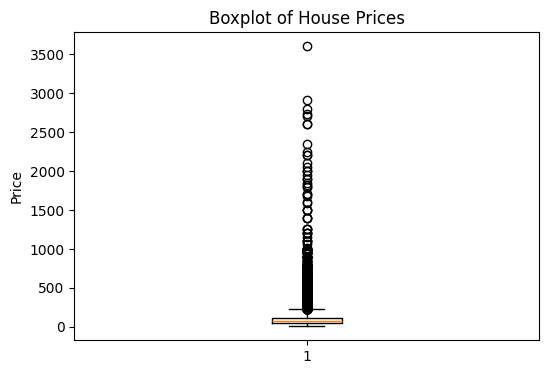

In [35]:
df = pd.read_csv("bhp.csv")

plt.figure(figsize=(6, 4))
plt.boxplot(df['price'].dropna())
plt.title("Boxplot of House Prices")
plt.ylabel("Price")
plt.show()

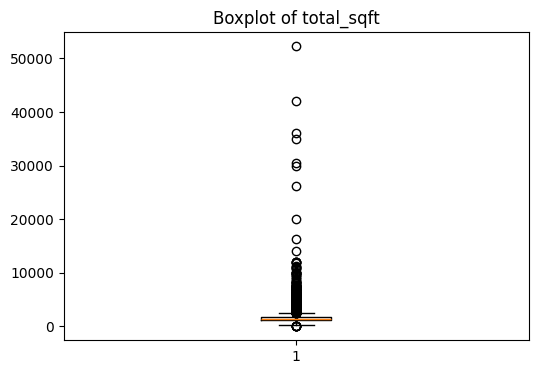

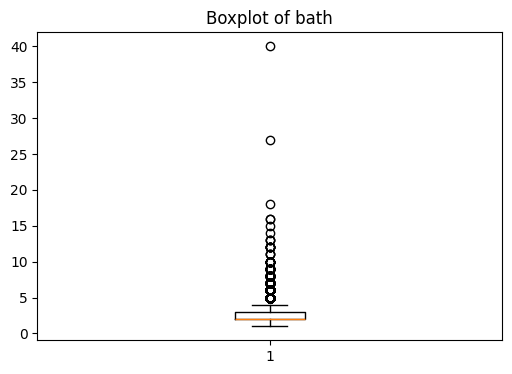

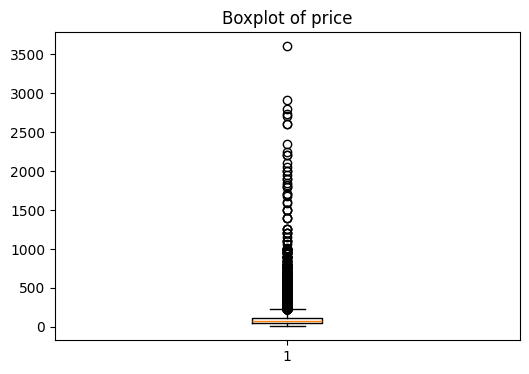

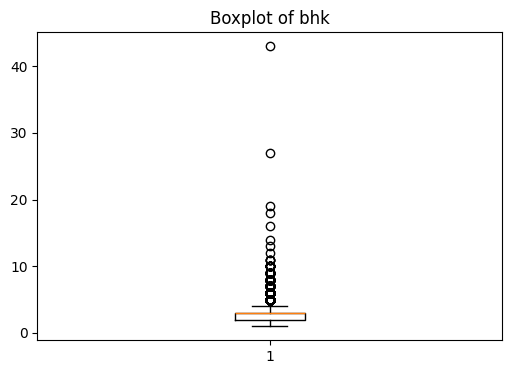

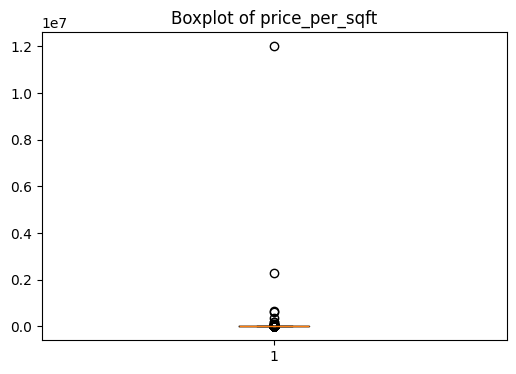

In [36]:
for col in ['total_sqft', 'bath', 'price', 'bhk', 'price_per_sqft']:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[col].dropna())
    plt.title("Boxplot of " + col)
    plt.show()

In [37]:
# Display cleaned dataset
print("\nCleaned Dataset:\n", df.head())
print("\nFinal Shape:", df.shape)
print("\nMissing Values:\n", df)


Cleaned Dataset:
                    location       size  total_sqft  bath   price  bhk  \
0  Electronic City Phase II      2 BHK      1056.0   2.0   39.07    2   
1          Chikka Tirupathi  4 Bedroom      2600.0   5.0  120.00    4   
2               Uttarahalli      3 BHK      1440.0   2.0   62.00    3   
3        Lingadheeranahalli      3 BHK      1521.0   3.0   95.00    3   
4                  Kothanur      2 BHK      1200.0   2.0   51.00    2   

   price_per_sqft  
0     3699.810606  
1     4615.384615  
2     4305.555556  
3     6245.890861  
4     4250.000000  

Final Shape: (13200, 7)

Missing Values:
                        location       size  total_sqft  bath   price  bhk  \
0      Electronic City Phase II      2 BHK      1056.0   2.0   39.07    2   
1              Chikka Tirupathi  4 Bedroom      2600.0   5.0  120.00    4   
2                   Uttarahalli      3 BHK      1440.0   2.0   62.00    3   
3            Lingadheeranahalli      3 BHK      1521.0   3.0   95.00   

In [38]:
print("\nAverage Price by Location:")
print(df.groupby('location')['price'].mean().head(10))



Average Price by Location:
location
Anekal                  16.000000
Banaswadi               35.000000
Basavangudi             50.000000
Bhoganhalli             22.890000
Devarabeesana Halli    124.833333
Devarachikkanahalli     62.714286
Electronic City         23.250000
Mysore Highway          36.875000
Rachenahalli            23.900000
Sector 1 HSR Layout    276.000000
Name: price, dtype: float64


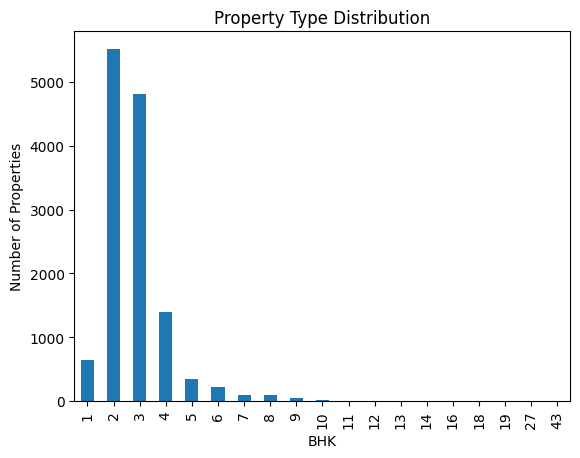

In [39]:
df['bhk'].value_counts().sort_index().plot(kind='bar')
plt.title("Property Type Distribution")
plt.xlabel("BHK")
plt.ylabel("Number of Properties")
plt.show()


In [40]:
print("\nAverage Price by BHK:")
print(df.groupby('bhk')['price'].mean())


Average Price by BHK:
bhk
1      44.179594
2      59.536929
3     110.954665
4     271.453090
5     280.200573
6     224.604545
7     244.370000
8     206.613636
9     240.461538
10    530.000000
11    207.500000
12    300.000000
13    275.000000
14    125.000000
16    550.000000
18    200.000000
19    490.000000
27    230.000000
43    660.000000
Name: price, dtype: float64


In [41]:
print("\nCleaned Dataset:")
print(df.head())

print("\nFinal Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

# 17. Save Cleaned Dataset
df.to_csv("Cleaned_Real_Estate.csv", index=False)

print("\nCleaned Dataset Saved Successfully!")



Cleaned Dataset:
                   location       size  total_sqft  bath   price  bhk  \
0  Electronic City Phase II      2 BHK      1056.0   2.0   39.07    2   
1          Chikka Tirupathi  4 Bedroom      2600.0   5.0  120.00    4   
2               Uttarahalli      3 BHK      1440.0   2.0   62.00    3   
3        Lingadheeranahalli      3 BHK      1521.0   3.0   95.00    3   
4                  Kothanur      2 BHK      1200.0   2.0   51.00    2   

   price_per_sqft  
0     3699.810606  
1     4615.384615  
2     4305.555556  
3     6245.890861  
4     4250.000000  

Final Shape: (13200, 7)

Missing Values:
location          0
size              0
total_sqft        0
bath              0
price             0
bhk               0
price_per_sqft    0
dtype: int64

Cleaned Dataset Saved Successfully!
